# Exploratory Data Analysis: Singapore Firms, FY2023

## 1. Load the Merged Dataset

In [9]:
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_FILE = (
    PROJECT_ROOT
    / "data"
    / "interim"
    / "orbis_singapore_fy2023_merged.parquet"
)

if not DATA_FILE.exists():
    raise FileNotFoundError(f"File not found: {DATA_FILE}")

df = pd.read_parquet(DATA_FILE)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
print(df.head())


Rows: 48,995
Columns: 28
                    Company name Latin alphabet Inactive Quoted Branch  \
0                      NVIDIA SINGAPORE PTE LTD       No     No     No   
1                            VITOL ASIA PTE LTD       No     No     No   
2  CLOUD NETWORK TECHNOLOGY SINGAPORE PTE. LTD.       No     No     No   
3                  WILMAR INTERNATIONAL LIMITED       No    Yes     No   
4                 GOOGLE ASIA PACIFIC PTE. LTD.       No     No     No   

  OwnData Woco Country ISO code NACE Rev. 2, core code (4 digits)  \
0      No   No               SG                              4652   
1      No   No               SG                              4671   
2      No   No               SG                              2620   
3      No  Yes               SG                              1042   
4      No  Yes               SG                              6391   

  Consolidation code BvD ID number  ... GUO - BvD ID number  \
0                 U1  SG200003831M  ...         US94

## 2. Inspect Columns, Data Types, and Recorded Missing Values

In [10]:
column_overview = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str).to_numpy(),
    "Missing count": df.isna().sum().to_numpy(),
    "Missing (%)": (
        df.isna().mean() * 100
    ).round(2).to_numpy(),
})

# Display all 28 columns 
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
):
    display(column_overview)

,Column,Data type,Missing count,Missing (%)
0,Company name Latin alphabet,string,0,0.00
1,Inactive,string,0,0.00
2,Quoted,string,0,0.00
3,Branch,string,0,0.00
4,OwnData,string,0,0.00
5,Woco,string,0,0.00
6,Country ISO code,string,0,0.00
7,"NACE Rev. 2, core code (4 digits)",string,0,0.00
8,Consolidation code,string,0,0.00
9,BvD ID number,string,0,0.00


## 3. Identify Missing-Value Placeholders in Size Measures

In [11]:
numeric_columns = [
    "Total assets th USD 2023",
    "Operating revenue (Turnover) th USD 2023",
    "Number of employees 2023",
]

conversion_checks = []

for column in numeric_columns:
    original = df[column].astype("string").str.strip()

    # Inspect conversion without changing df.
    numeric = pd.to_numeric(original, errors="coerce")

    failed = original.notna() & numeric.isna()

    conversion_checks.append({
        "Column": column,
        "Original missing": int(original.isna().sum()),
        "Text not converted": int(failed.sum()),
        "Missing after conversion (%)": round(
            numeric.isna().mean() * 100, 2
        ),
    })

    print(f"\n{column}")
    print("Most common entries that could not be converted:")
    print(original.loc[failed].value_counts().head(10))

display(pd.DataFrame(conversion_checks))


Total assets th USD 2023
Most common entries that could not be converted:
Series([], Name: count, dtype: Int64)

Operating revenue (Turnover) th USD 2023
Most common entries that could not be converted:
Operating revenue (Turnover) th USD 2023
n.a.    315
Name: count, dtype: Int64

Number of employees 2023
Most common entries that could not be converted:
Number of employees 2023
n.a.    48720
Name: count, dtype: Int64


,Column,Original missing,Text not converted,Missing after conversion (%)
0,Total assets th USD 2023,0,0,0.00
1,Operating revenue (Turnover) th USD 2023,0,315,0.64
2,Number of employees 2023,0,48720,99.44


## 5. Prepare an EDA Copy and Compare Data Availability

Create a working copy, convert assets, revenue, and employee counts to numeric values, and compare data availability between listed and unlisted firms.

In [12]:
# Make a working copy without changing the original data.
eda = df.copy()

size_columns = {
    "Total assets th USD 2023": "assets_th_usd",
    "Operating revenue (Turnover) th USD 2023": "revenue_th_usd",
    "Number of employees 2023": "employees",
}

# Convert numeric text to numbers; "n.a." becomes missing.
for original, new in size_columns.items():
    eda[new] = pd.to_numeric(
        eda[original].astype("string").str.strip(),
        errors="coerce",
    )

eda["listing_status"] = (
    eda["Listing status"]
    .astype("string")
    .str.strip()
    .fillna("Missing")
)

# Check availability separately within each listing group.
availability_rows = []

for group, sample in eda.groupby("listing_status"):
    for variable in size_columns.values():
        availability_rows.append({
            "Listing status": group,
            "Variable": variable,
            "Total firms": len(sample),
            "Available": int(sample[variable].notna().sum()),
            "Missing (%)": round(
                sample[variable].isna().mean() * 100, 2
            ),
        })

availability_table = pd.DataFrame(availability_rows)

display(availability_table)

,Listing status,Variable,Total firms,Available,Missing (%)
0,Listed,assets_th_usd,496,496,0.00
1,Listed,revenue_th_usd,496,493,0.60
2,Listed,employees,496,267,46.17
3,Unlisted,assets_th_usd,48499,48499,0.00
4,Unlisted,revenue_th_usd,48499,48187,0.64
5,Unlisted,employees,48499,8,99.98


## 6. Check Numeric Values and Summarise Firm Size

Count missing, zero, negative, and infinite values, then summarise the available finite observations by listing status. Assets and revenue are measured in thousands of USD; employees are headcounts.

In [13]:
import numpy as np

summary_rows = []

for group, sample in eda.groupby("listing_status"):
    for variable in ["assets_th_usd", "revenue_th_usd", "employees"]:
        values = sample[variable].astype("float64")

        # Exclude missing and infinite values from summaries only.
        finite_values = values[np.isfinite(values)]

        summary_rows.append({
            "Listing status": group,
            "Variable": variable,
            "Total firms": len(sample),
            "Missing": int(values.isna().sum()),
            "Infinite": int(np.isinf(values).sum()),
            "Zero": int(finite_values.eq(0).sum()),
            "Negative": int(finite_values.lt(0).sum()),
            "Finite count": len(finite_values),
            "Minimum": finite_values.min(),
            "25th percentile": finite_values.quantile(0.25),
            "Median": finite_values.median(),
            "Mean": finite_values.mean(),
            "75th percentile": finite_values.quantile(0.75),
            "99th percentile": finite_values.quantile(0.99),
            "Maximum": finite_values.max(),
        })

size_summary = pd.DataFrame(summary_rows)

with pd.option_context(
    "display.max_columns", None,
    "display.width", 200,
):
    display(size_summary.round(2))

,Listing status,Variable,Total firms,Missing,Infinite,Zero,Negative,Finite count,Minimum,25th percentile,Median,Mean,75th percentile,99th percentile,Maximum
0,Listed,assets_th_usd,496,0,0,0,0,496,9.94,31417.96,96719.23,1449629.43,565607.18,25483804.93,61808692.0
1,Listed,revenue_th_usd,496,3,0,2,0,493,0.00,17099.20,61438.85,671396.48,197427.58,14136956.84,67715457.0
2,Listed,employees,496,229,0,0,0,267,1.00,70.50,281.00,2779.48,842.50,53250.04,148000.0
3,Unlisted,assets_th_usd,48499,0,0,531,19,48499,-2919.17,142.88,978.48,44225.41,6972.41,687659.58,79846617.1
4,Unlisted,revenue_th_usd,48499,312,0,10292,56,48187,-8419.19,9.99,493.62,50733.56,3786.50,656002.78,83465374.0
5,Unlisted,employees,48499,48491,0,0,0,8,26.00,257.25,742.00,1515.75,1516.75,6109.36,6372.0


### observations

Listed firms have substantially higher median assets and revenue than
unlisted firms in the merged sample. Means greatly exceed medians in both
groups, suggesting strongly right-skewed size distributions.

Employee counts are available for 267 listed firms but only 8 unlisted
firms. Employee-based comparisons would therefore describe a highly
selected subset and will not be treated as a main EDA comparison.

Zero and negative financial values require investigation. These results
are descriptive and precede sample exclusions and matching; they do not
establish that listing causes larger firm size.

## 7. Compare Assets and Revenue Distributions

Plot positive assets and revenue on a logarithmic scale by listing status.
Missing, zero, and negative values are excluded from these plots only.


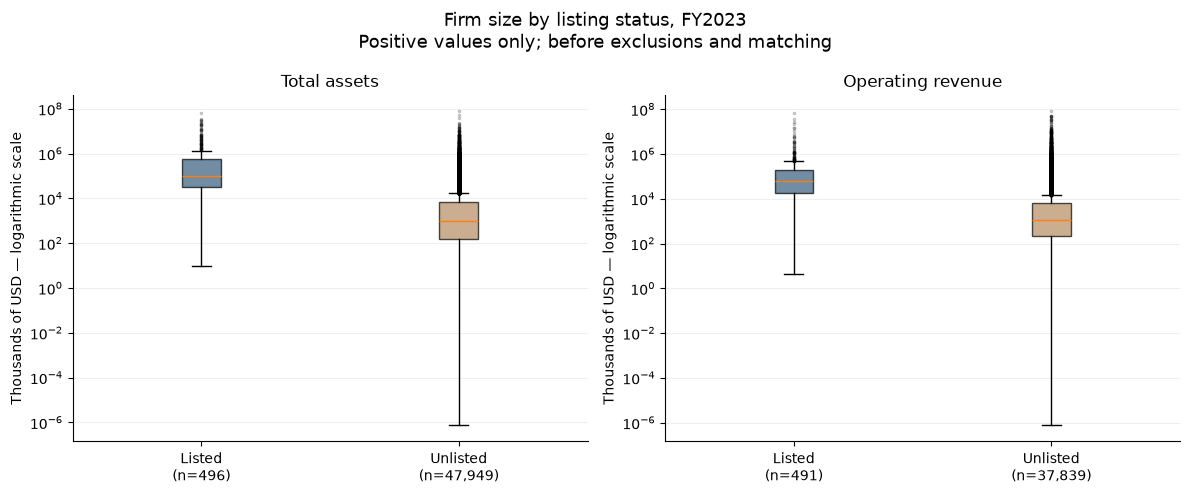

In [14]:
import matplotlib.pyplot as plt
import numpy as np

groups = ["Listed", "Unlisted"]
colors = ["#355C7D", "#B58B61"]

variables = {
    "assets_th_usd": "Total assets",
    "revenue_th_usd": "Operating revenue",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (variable, title) in zip(axes, variables.items()):
    plot_values = []
    labels = []

    for group in groups:
        values = (
            eda.loc[eda["listing_status"].eq(group), variable]
            .astype("float64")
        )

        positive = values[np.isfinite(values) & values.gt(0)]

        plot_values.append(positive.to_numpy())
        labels.append(f"{group}\n(n={len(positive):,})")

    boxes = ax.boxplot(
        plot_values,
        patch_artist=True,
        showfliers=True,
        flierprops={
            "marker": ".",
            "markersize": 3,
            "alpha": 0.25,
        },
    )

    for box, color in zip(boxes["boxes"], colors):
        box.set_facecolor(color)
        box.set_alpha(0.7)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(labels)
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_ylabel("Thousands of USD — logarithmic scale")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Firm size by listing status, FY2023\n"
    "Positive values only; before exclusions and matching",
    fontsize=13,
)

plt.tight_layout()
plt.show()

## 8. Investigate Very Small Positive Financial Values

Count positive assets and revenue below US$1 and inspect their most
common values.

In [15]:
# Values are in thousands of USD:
# 0.001 thousand USD = US$1.

for variable in ["assets_th_usd", "revenue_th_usd"]:
    values = eda[variable].astype("float64")

    tiny = values.gt(0) & values.lt(0.001)

    print(f"\n{variable}: positive values below US$1")

    print(
        pd.crosstab(
            eda["listing_status"],
            tiny,
        ).rename(columns={
            False: "Other or missing",
            True: "Positive below US$1",
        })
    )

    print("\nMost common tiny values, in thousands of USD:")
    print(values.loc[tiny].value_counts().head(10))


assets_th_usd: positive values below US$1
assets_th_usd   Other or missing  Positive below US$1
listing_status                                       
Listed                       496                    0
Unlisted                   48281                  218

Most common tiny values, in thousands of USD:
assets_th_usd
0.000758    93
0.001000    54
0.000738    18
0.000733     8
0.000742     7
0.000751     7
0.000999     6
0.000739     3
0.001000     3
0.000732     3
Name: count, dtype: int64

revenue_th_usd: positive values below US$1
revenue_th_usd  Other or missing  Positive below US$1
listing_status                                       
Listed                       496                    0
Unlisted                   48383                  116

Most common tiny values, in thousands of USD:
revenue_th_usd
0.000008    30
0.000010    23
0.000758    11
0.000008     4
0.000007     3
0.001000     3
0.000733     3
0.000010     3
0.000739     3
0.000010     3
Name: count, dtype: int64
